# ComCon Vignette 2: Multi-Species Community Connectivity

**Identifying connectivity hotspots across a three-species rocky shore community using Network Analysis (Type 2)**

---

## What This Vignette Covers

This vignette extends the single-species workflow from Vignette 1 to a multi-species community analysis. Using three common rocky shore species with contrasting dispersal strategies, we identify which coastal sites are most important for maintaining connectivity across the community as a whole.

By the end, you will have:

- Run a multi-species simulation with three rocky shore species
- Run Type 2 network analysis to identify connectivity hotspots, stepping stones as well as key source and sink populations
- Learned how to interpet the network maps and connectivity matrices

### Why Multi-Species Analysis?

Single-species connectivity models tell us about one species in isolation. But in reality, marine communities contain many interacting species with different life history traits. Using one or two focal species as surrogates for the wider community when it comes to spatial planning and conservation management has significant limitations as similar life histories do not necessarily produce similar dispersal patterns. A site that is unimportant for one species may be critical for another. Community-level analysis combines information across species to identify sites that matter for the system as a whole.

### Why Network Analysis?

Type 1 connectivity metrics (Vignette 1) tell us *how far* and *how many* larvae disperse. Type 2 network analysis goes further by asking *where* they go and *which sites* play the most important roles in maintaining the network. It treats your study area as a network of connected sites and uses graph theory to identify:

- **Source sites** that export larvae to many other locations
- **Sink sites** that receive larvae from many other locations
- **Stepping stones** that bridge otherwise disconnected parts of the network
- **Connectivity hotspots** that rank highest across multiple network metrics

### What You Will Need

- ComCon installed in a Conda environment (see the User Guide, Part 1)
- A free Copernicus Marine Service account ([register here](https://data.marine.copernicus.eu/register))
- Approximately 3 hours (including simulation time, which is longer than a single-species analysis due to the extended spawning period across three species)

### Study Species

<img src="multi_spp.jpg" alt="The three study species on rocky shores in south-west England" style="max-width: 1200px; width: 100%;">

Photo: The three study species on rocky shores across south-west England. Credit: Laura Bachmaier

*Patella vulgata* (common limpet), *Semibalanus balanoides* (acorn barnacle) and *Littorina littorea* (common periwinkle) are among the most abundant species on NE Atlantic rocky shores. Together they structure intertidal communities through grazing, space occupation and trophic interactions and their population dynamics are widely used as indicators of rocky shore health. All three are broadcast spawners that release larvae into the water column, but they greatly differ in how long those larvae spend in the plankton (their planktonic larval duration or PLD), ranging from as few as 2 days (*P. vulgata*) to as many as 60 days (*S. balanoides*). 

This range of pelagic larval durations makes them an ideal test case for multi-species connectivity modelling, as it allows us to examine how contrasting dispersal strategies produce different connectivity networks across the same seascape. In addition, their PLD range broadly encompasses that of many other intertidal invertebrates, allowing them to act as umbrella species for the wider rocky shore community and will allow us to assess how we might want adjust conservation management of our coastlines to suit the needs of the many, not just the few. 

<table style="text-align: left; margin-left: 0;">
  <thead>
    <tr>
      <th>Species</th>
      <th>Common Name</th>
      <th>Spawning Season</th>
      <th>PLD</th>
      <th>Dispersal Strategy</th>
      <th>Link</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><em>Patella vulgata</em></td>
      <td>Common limpet</td>
      <td>October – January</td>
      <td>2–10 days</td>
      <td>Short</td>
      <td>https://www.marlin.ac.uk/species/detail/1371</td>
    </tr>
      <tr>
      <td><em>Littorina littorea</em></td>
      <td>Common periwinkle</td>
      <td>February – June</td>
      <td>11–30 days</td>
      <td>Medium</td>
      <td>https://www.marlin.ac.uk/species/detail/1328</td>
    </tr>
    <tr>
      <td><em>Semibalanus balanoides</em></td>
      <td>Acorn barnacle</td>
      <td>February – April</td>
      <td>21–60 days</td>
      <td>Long</td>
      <td>https://www.marlin.ac.uk/species/detail/1346</td>
    </tr>
  </tbody>
</table>

### Research Questions
Each ComCon vignette addresses a different type of ecological question using the same underlying simulation framework:

**Vignette 1** (this vignette):

→ **Type 1: Connectivity Metrics**
- What are the general dispersal characteristics of *P. vulgata* along the southern English coast? For example:
    - How many larvae successfully settle?
    - How far do they travel?
    - Are populations self-sustaining through local recruitment or do they depend on larval supply from elsewhere?

**Vignette 2:** 

→ **Type 2: Network Analysis**
- Which sites are most important for maintaining connectivity across the community?
- Where are the connectivity hotspots, stepping stones and key source populations?
- Where are critical sink populations dependent on external larval supply?

**Vignette 3:** 

→ **Type 3: Trait Sensitivity Analysis**
- Which connectivity hotspots are robust to trait uncertainty and which are fragile?
- Do species-specific dispersal traits significantly shape connectivity patterns or are patterns primarily driven by oceanographic currents and coastal geography?
- What happens to the connectivity network if spawning windows shift (e.g. under climate change)?

### Before You Begin

A few things to note as you work through this vignette:
 
- This vignette uses **Manual Mode** throughout, calling functions directly. If you have completed Vignette 1.2, the approach will be familiar.
- Several functions include interactive prompts (marked with `[I]` in the function list). These will ask you to enter values such as Copernicus credentials, species selections and study area boundaries.
    - The values to enter at each prompt are explained in the text before each code cell.
- File paths and folder locations will depend on your own computer setup. Wherever the vignette shows a file path, yours will be different. Just make sure you know where your working directory is.
- Saving prompts: ComCon will occasionally ask whether you want to save outputs (e.g., "Do you want to export the data to a NetCDF file?") or review parameters. These prompts are not described in detail below as the choices depend on your preferences. When in doubt, the defaults (shown in square brackets) are a safe choice.
- Parameter files: ComCon automatically saves your settings to JSON files (e.g., hydrodynamic_parameters.json) so you can reload them later without re-entering everything.
- **Continuing to Vignette 3:** If you plan to run Vignette 3, you will need to save your grid data during **Step 3** when prompted by `save_grids()`. This includes the release grids, settlement grids, full grid, grid IDs, coastal grid and mapping grid. Your species traits (Step 1) and simulation output (Step 4) are saved automatically. With these saved, Vignette 3 can reload everything and re-run the post-processing with modified traits, no new simulation required.
- **Temporal buffer:** This vignette includes a temporal buffer (30 days before and after the combined spawning period). This extends the simulation window slightly so that the trajectory data can be reused in Vignette 3 for trait sensitivity analysis without needing to re-run the simulation. It does not affect the results in this vignette.

### Getting Started

Open a new notebook in Jupyter Lab and make sure your `comcon` environment is active (you should see `(comcon)` in your terminal). If you need help with this, see the User Guide, Part 1.

Import ComCon by running the cell below. You will see the ComCon welcome message and the option to select your mode.

When the mode selection appears, choose Manual Mode and click Start.

You will see a message explaining Manual Mode.

---


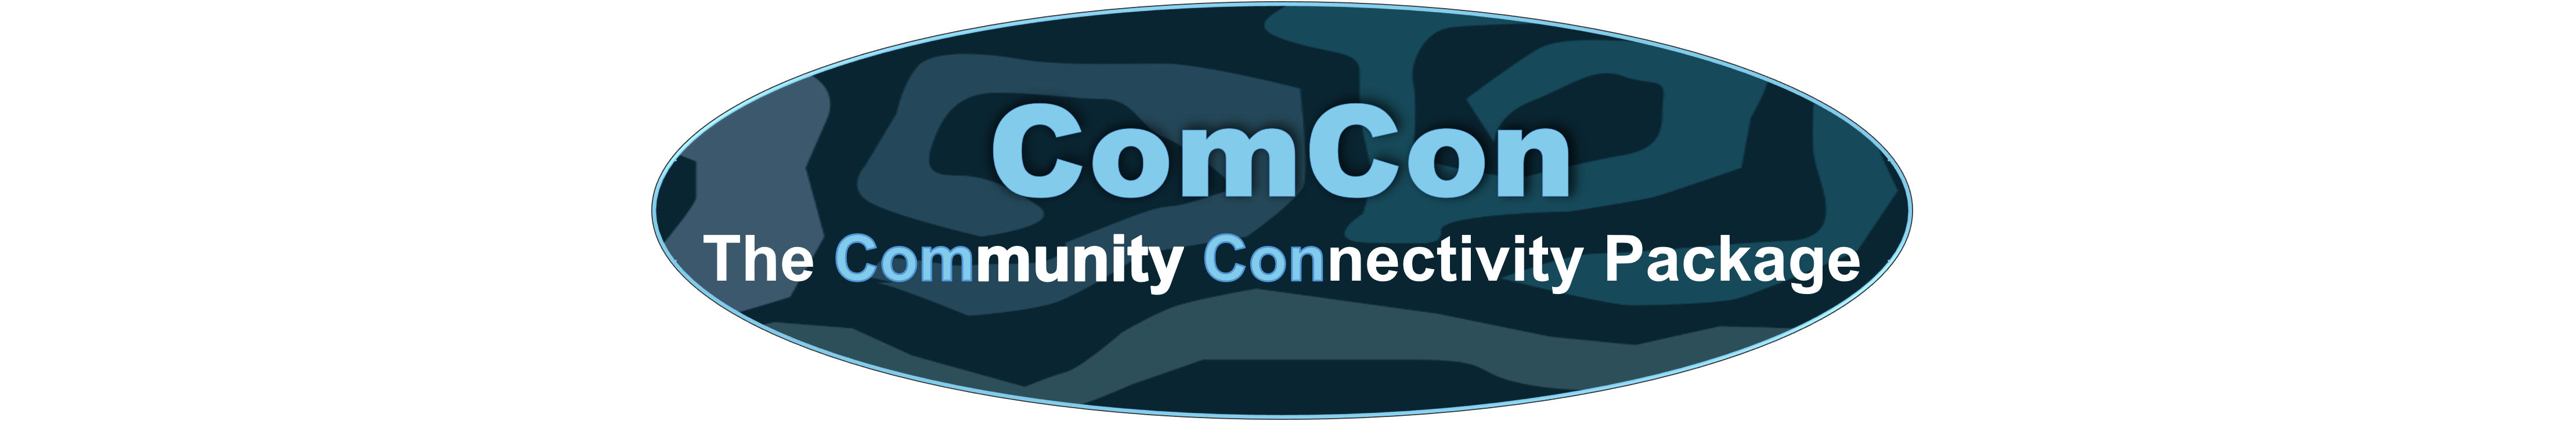


Welcome to ComCon!

This package facilitates multi-species dispersal modeling using Lagrangian particle tracking with Ocean Parcels and NEMO hydrodynamic data.

You can use the package in three modes:
  1. Interactive Mode: Step-by-step guided workflow
  2. Automatic Mode: Run entire workflow with preset parameters
  3. Manual Mode: Access individual functions for custom workflows



Please select a mode below:


Dropdown(description='Mode:', options=(('Interactive Mode', 'interactive'), ('Automatic Mode', 'automatic'), (…

Button(button_style='success', description='Start', icon='check', style=ButtonStyle())

Output(layout=Layout(height='0px', overflow='hidden'))

In [1]:
import comcon

In [2]:
from comcon.manual import *

> **Tip:** To see all available functions, run `list_functions()`. To see example workflows, run `example_workflow()`.

---

## Step 1: Hydrodynamic and Trait Data

This step collects your Copernicus Marine Service credentials, hydrodynamic extent, species trait data and the start year for the dispersal season. It then downloads the hydrodynamic data.

The `params()` function will prompt you for:

**Loading hydrodynamic data**
- Select Option 1: Download from Copernicus Marine Service

**Copernicus credentials:**
- Username and password for your Copernicus Marine Service account

**Dataset selection:**
- Use dataset ID: `cmems_mod_nws_phy-cur_anfc_1.5km-2D_PT1H-i`

For this example we will assess the connectivity of a three-species rocky shore community across the south-west of the English Channel (Devon and Cornwall). We are using the same hydrodynamic data as Vignette 1.

**Hydrodynamic extent:**
- Longitude range: -7 to 2 
- Latitude range: 48 to 52

Remember that the spatial extent of your hydrodynamic data needs to be much larger than your actual study area for which you are assessing connectivity of a given species. The hydrodynamic extent is the entire area in which your propagules can disperse not just settle within. Therefore, choosing an area on the generously bigger side is a safer bet in case some of your propagules travel very large distances.

**Species traits:**
- When asked for a trait source, choose **Built-in database**
- Select all three species: 22-*Patella vulgata*, 13-*Littorina littorea* and 26-*Semibalanus balanoides*
- The trait values will be loaded automatically

**Temporal buffer:**
- If wanting to run Vignette 3: Trait sensitivity analysis select yes for **Add temporal buffer?**
- Enter **30 days** for both the before and after buffer

- If not, select no for **Add temporal buffer?**

The temporal buffer extends the simulation window beyond the simulation period calculated from the trait data. This is needed for Vignette 3 (trait sensitivity analysis), where we test what happens if spawning windows shift. Without a buffer, there would be no trajectory data outside the original spawning window to test alternative scenarios. A 30-day buffer is sufficient for the sensitivity tests we will run.

**Saving the hydrodynamic data:**

When prompted, you will have the option to either **export** the data to a **NetCDF** file on your computer or load it directly into your Python environment using **lazy loading**. 

- We recommend choosing **lazy loading** (i.e., selecting "no" when asked whether to export to NetCDF)

Lazy loading streams the data from the Copernicus servers as needed rather than downloading the entire file to your hard drive first. This is faster, avoids creating very large files on your computer (hydrodynamic datasets can be several gigabytes) and is how we run all the examples in these vignettes. The data will remain available in your `hydro_data` variable for the rest of the workflow or until you re-start the Kernel. 

If you do choose to export the data as a NetCDF file, be aware that the download can take a long time depending on the size of your study area, the length of the simulation period and your internet connection speed. For reference, the single species example in this vignette can take up to several hours to download as a NetCDF file. The advantage of saving to file is that you can reload the data later without re-downloading, which is useful if you plan to re-run the same analysis multiple times or need the data for other analyses.

**Simulation year:**
- Choose **2024** as the start year of this simulation

ComCon will calculate the combined simulation period based on all three species' spawning seasons and PLDs, plus the temporal buffer. The simulation will cover approximately October 2024 to late July 2025.

---

Now run the next cell, to set your parameters:

In [ ]:
# Step 1a: Collect all parameters

hydro_params, species_traits_path, runtime, traits = params()

Now use the `download_hydrodynamic_data()` function to load the hydrodynamic data using the parameters collected above. This may take several minutes depending on your internet connection.

In [ ]:
# Step 1b: Download hydrodynamic data from Copernicus

hydro_data = download_hydrodynamic_data(**hydro_params)

---

## Step 2: Species Occurrence Data

ComCon needs to know where each species is found so it can set up appropriate release and settlement locations. The `spp_occ()` function handles the entire species occurrence workflow for all three species: downloading records from GBIF, creating habitat masks and filtering the data to your study area.

**What ComCon will ask you:**

**Study area polygon:**
- When prompted, draw a polygon on the interactive map covering the southern English coast, similar to the one drawn below in the example

<img src="study_area.jpg" alt="Study area selection of the South-West of England" style="max-width: 600px; width: 100%;">

*Photo: Study area selection of the South-West of England.*

This polygon defines where you want to focus your connectivity analysis. Alternatively, you can load an existing GeoJSON file, if you have one.

**Data source:**
- Choose GBIF

ComCon will search GBIF for occurrence records for all three species within your study area.

**Habitat filtering:**
- Choose Coastal

This is appropriate for intertidal rocky shore species. ComCon will create land and coastal masks from the hydrodynamic data and filter out any occurrence records that fall on land or in the open ocean.

You will see a summary for each species showing how many records were downloaded and how many remain after data cleaning.

> **Tip:** If you have your own species distribution data (e.g., from field surveys), you can upload it as a CSV file instead of using GBIF. See the User Guide, Part 5 for the required CSV format.

In [ ]:
# Step 2: Download and clean species occurrence data

clean_spp, spp_params, landmask, coastalmask, lonarray, latarray = spp_occ(
    hydro_data, species_traits_path
)

---

## Step 3: Release and Settlement Setup

This step maps the species occurrence data onto the hydrodynamic model grid to create release sites (where particles start) and settlement sites (where particles can end up). It also creates the OceanParcels fieldset that will drive the particle simulation and sets up reflective boundaries to prevent particles from getting stuck on land.

In Manual Mode, this step uses four functions. First, `setup_release_settlement()` sets up the release and settlement sites. Then, `create_fieldset()` builds the OceanParcels fieldset from your hydrodynamic data. Next, `create_pset()` creates the particle set and prompts you for your release preferences. Finally, `create_custom_kernels()` defines the rules governing how particles behave (advection by currents, random diffusion and boundary interactions).

### What ComCon Will Ask You

#### Release and Settlement Strategy
- For release sites choose Option 2: Species-specific habitat (based on GBIF data)
- For settlement sites choose Option 2: Species-specific habitat (same as release data)

In a multi-species analysis, each species gets its own set of release and settlement sites based on where it is recorded. Particles for *P. vulgata* will only be released from sites where *P. vulgata* is currently found.

#### Release interval
- Choose weekly

Weekly releases capture temporal variation in ocean current conditions throughout the combined spawning seasons, ensuring that larvae experience a representative range of hydrodynamic conditions whilst still keeping the total particle count manageable.

#### Number of Particles
- Go with the default of 100

In a realistic simulation you will want to set the particle number much higher, e.g. 1000–10000. This does not represent the actual number of larvae being released but rather the resolution at which you are sampling possible dispersal pathways. Think of it like sample size. By increasing the number of particles, you increase the likelihood of capturing rare but important long-distance connections and produce more stable, reproducible connectivity estimates. For this example, 100 is sufficient to demonstrate the workflow and see general patterns.

#### Horizontal Diffusivity
- Go with the default of 1 m²/s

This is representative of standard small-scale random motion caused by turbulence in marine systems.

ComCon will display a summary showing how many release and settlement sites were created. It will also create the OceanParcels fieldset (the velocity field used to advect particles) and set up reflective boundaries to prevent particles from getting stuck on land.

---

> **Note:** Here there are brackets around the input variables `(meshgrid, release grids...)`. This is only added as the number of parameters is split across two lines and it tells Python to read them as one statement.

In [ ]:
# Step 3a: Set up release and settlement grids

(meshgrid, release_grids, settlement_grids, full_grid_df, grid_ids, coastal_grid, coastal_grid_df,
 coastal_grid_filtered, grid_df_for_mapping) = setup_release_settlement(
            coastalmask, landmask, clean_spp, spp_params, lonarray, latarray)

Now create the OceanParcels fieldset. This converts your hydrodynamic data into the velocity field that OceanParcels will use to advect (transport) particles. It also calculates reflective boundary vectors from the land mask so that particles move away from the coastline rather than getting stranded on land.

In [ ]:
# Step 3b: Create OceanParcels fieldset

fieldset = create_fieldset(hydro_data, landmask, grid_ids)

Now create the particle set. This is where you configure how many particles to release, how often and with what diffusivity. A particle set is simply a collection of virtual particles with defined starting positions, release timing and behavioural rules.

Here, as noted above, choose:

- A **weekly** release interval
- The default of **100** particles to release per site and release interval
- The default of **1 m²/s**

In [ ]:
# Step 3c: Create particle set

pset, adjusted_runtime, interval, repeatdt = create_pset(
    fieldset, meshgrid, runtime)

Finally, create the particle behaviour kernels. These define the rules that govern how each particle moves at every timestep.

In [ ]:
# Step 3d: Create particle behaviour kernels

kernels = create_custom_kernels(pset)

---

## Step 4: Running the Simulation

This is the computationally intensive step. Using the `execute_simulation()` function, ComCon tracks all particles through the ocean current field over the full simulation period using OceanParcels.

**Important:** In a multi-species analysis, ComCon runs a single shared simulation that covers the full temporal window for all species. The species-specific filtering (spawning season, PLD) happens during post-processing (Step 5). This is computationally efficient because it avoids running separate simulations for each species.

### What ComCon Will Ask You

#### Output path
- Provide a file path and name for the simulation output

The raw simulation output will be saved as a .zarr file.

#### Output frequency
- Choose 24 hours

Output frequency controls how often particle positions are recorded during the simulation. The default of 24 hours is fine for most analyses. It keeps file sizes manageable while providing daily position data. Higher frequency (e.g., 6 hours) gives more temporal detail but produces larger files.

#### Time step
- Choose the default of 60 minutes

#### Memory check
ComCon will automatically check your system's available RAM and adjust processing chunk sizes accordingly. You do not need to do anything here. This is just informational. 

ComCon will then display a summary of simulation settings (runtime, output frequency, time step) and begin running the OceanParcels simulation with a progress bar. Because the combined spawning period across all three species is longer than in Vignette 1, the simulation will take longer to run.

> **Tip:** If the simulation runs slowly or you experience memory issues, try reducing the number of particles or the study area extent. See the Troubleshooting section in the User Guide.

In [ ]:
# Step 4: Run simulation

output_path, traj = execute_simulation(
    pset, kernels, adjusted_runtime, interval
)

---

## Step 5: Post-Processing

The raw simulation output contains all particle trajectories regardless of biological constraints. Post-processing, our other most time-intensive step of this workflow, applies three sequential filters to extract only the trajectories that are biologically relevant **for each species** using the `post_process()` function:

1. **Spawning filter:** Retains only particles released during each species' spawning window. For example, for *P. vulgata*, particles released in March are discarded (outside Oct–Jan window), while *S. balanoides* particles released in October are discarded (outside Feb–Apr window).
2. **PLD filter:** Crops each trajectory to the species' pelagic larval duration and checks whether the particle reached suitable settlement habitat within that time. A *P. vulgata* particle must settle within 2–10 days; a *L. littorea* particle has 28–56 days.
3. **Habitat filter:** Confirms particles were released from suitable habitat for that species.

### What ComCon Will Ask You

**Settlement buffer:**
- Choose a buffer of 1 cell

ComCon will ask for a buffer size (in grid cells) around settlement sites.  A buffer of 1 allows particles to settle if they are within one grid cell of a known settlement location, accounting for the fact that grid cells may not perfectly align with actual habitat.

After filtering, ComCon will display a summary for each species showing how many trajectories passed each filter. You will typically see large reductions, particularly for the spawning filter. This is expected since the shared simulation covers the full combined spawning period but each species only uses a fraction of it.

---

In [ ]:
# Step 5: Post-process trajectories

final_processed, buffer = post_process(
    traj, traits, release_grids, settlement_grids, grid_ids
)

---

## Step 6: Type 2 Network Analysis

This is where we address our research question: Which sites are most important for maintaining connectivity across the community? 

Type 2 analysis uses network analysis, or graph theory, to treat each coastal site as a node in a network. If larvae travel from site A to site B, that creates a directed connection (edge) in the network. The analysis then calculates a range of network metrics to determine how sites are connected and which are most important for different aspects of connectivity.

In Manual Mode, we call `network_analysis()` directly rather than using the `post_analysis()` wrapper. This gives us full control over the inputs and allows us to run community-level and per-species analyses separately.

### What the Network Metrics Tell You

The metrics fall into two categories:

- **Source strength:** Total larvae dispersing from a site (to all destinations, including back to itself). High source sites are important larval producers for the wider network.
- **Sink strength:** Total larvae settling at a site (from all origins, including from itself). High sink sites depend on external larval supply.
- **Local recruitment:** Larvae that return to settle at their release site. High values indicate more self-sustaining populations. 

**Centrality measures:**
- **Betweenness centrality:** How often a site lies on the shortest path between other sites. Sites scoring high represent important stepping stones meaning that if removed, connectivity between other sites would decrease.
- **Closeness centrality:** How close a site is (on average) to all other sites in the network. High closeness sites can reach the rest of the network quickly.
- **Degree centrality:** How many direct connections a site has. High degree sites are well-connected hubs.

These metrics can be combined into **composite scores** that identify the top connectivity hotspots which are sites that consistently rank highly across multiple metrics.

### What ComCon Will Ask You

**Distance threshold:**
- Use **Full domain**

The distance threshold filters out very long-distance connections that may be rare or unreliable. A threshold of 30 km means that only connections where larvae travel 30 km or less are included in the network. This focuses the analysis on the most ecologically meaningful connections.

### Per-Species Network Analysis

We can also run network analysis for each species individually. This lets us compare how different dispersal strategies produce different connectivity networks. Do the same sites appear as hotspots for all three species, or does each species have its own important sites?

### Understanding the Distance Threshold

`network_analysis()` accepts a distance threshold parameter (`null_scale`) that controls the spatial scale of the analysis. When set, it filters out connections longer than the specified distance. For example, a threshold of 30 km retains only short-range connections, which may be useful for examining local connectivity patterns or for species with short PLDs. Setting `null_scale=None` retains all connections regardless of distance. Running the analysis at multiple thresholds allows comparison of local versus regional connectivity patterns. For this vignette, we use the full domain (`None`) to capture the complete network structure.

### Community-Level Network Analysis

First, we run the network analysis at the community level, combining all three species. This tells us which sites are most important when we consider the full community's connectivity.

We pass `final_processed` (containing all three species' filtered trajectories), the release and settlement grids, and the grid data. Setting `null_scale=None` includes all connections regardless of distance.

### Per-Species Network Analysis

Next, we run the same analysis for each species individually. This lets us compare how different dispersal strategies produce different connectivity networks — do the same sites appear as hotspots for all three species, or does each species have its own set of important sites?

For each species, we create a single-species dictionary from `final_processed` and pass the corresponding species-specific settlement grid. We pass the full `release_grids` (all species) to maintain a consistent study extent across analyses, ensuring that the same set of coastal sites is considered for each species.

### Displaying the Results

After running the analysis, we use `create_network_map()` to visualise the results. This produces a map showing all connected sites coloured by their composite score, with the top 10 hotspots numbered.

The function takes the `site_metrics` DataFrame and the top 10 DataFrame from the network analysis results. The `composite_col` parameter controls which score is used for colouring — use `'overall_composite'` for the combined ranking, `'functional_composite'` for functional roles only, or `'centrality_composite'` for centrality measures only.

To display the connectivity matrix as a heatmap, use `create_connectivity_matrix_plot()` with the `connectivity_matrix` from the network results. This shows the strength of connections between all pairs of sites.

Run these for both the community-level and each per-species result to compare how the network structure differs across species.

We will call `network_analysis()` directly, passing in the required data:

In [ ]:
# Step 6: Run network analysis at community level

community_network = network_analysis(
    final_processed, release_grids, settlement_grids,
    grid_df_for_mapping, grid_ids, full_grid_df,
    null_scale=30
)

display_network_summary(community_network)

### Interpreting the Network Results

> Note: The results shown in this vignette will not match your results exactly because the model includes stochastic particle movement.

**Community-level hotspots:** The top 10 community-level hotspots represent the sites that are most important for maintaining connectivity across all three species combined. These are the sites that a marine spatial planner would want to prioritise for protection, as they benefit the entire community.

**Species-specific hotspots:** Comparing the per-species top 10 lists reveals how much agreement there is between species. If the same sites appear in all three lists, this suggests that oceanographic features (e.g. headlands, embayments, current convergence zones) drive connectivity regardless of PLD. If the lists differ, this indicates that species traits play a significant role in determining which sites matter.

**Connectivity matrix:** The connectivity matrix shows the flow of particles between all pairs of sites. Strong off-diagonal values indicate important long-distance connections. The matrix can reveal patterns such as predominantly westward or eastward transport driven by prevailing currents.

**Source vs sink patterns:** Sites with high source strength but low sink strength are net exporters of larvae. Sites with high sink strength but low source strength depend on external supply. Sites with high local recruitment may be more resilient to disturbance because they can partly self-replenish.

> Note: These results are based on a low-resolution example (100 particles per site per release event). For robust scientific conclusions, increase particle numbers and validate against field observations. Network metrics estimate potential connectivity based on physical transport and do not account for post-settlement survival or other biological processes.

---

## Summary

You have now completed a multi-species community connectivity analysis using ComCon by:

1. **Setting up** the ocean current data and trait data for three species with contrasting life histories
2. **Downloading** species occurrence data for all three species and mapping them to the model grid
3. **Running one shared simulation** that covers the full temporal window for all species
4. **Filtering** the shared trajectories through species-specific trait profiles to produce three separate connectivity datasets
5. **Running** Type 2 network analysis to identify connectivity hotspots at both the community and per-species level

The network analysis identified which sites play the most important roles in maintaining larval connectivity. Comparing the community-level and per-species results reveals how individual species contribute to the overall network structure.

### What Next?

- **Vignette 3: Trait Sensitivity Analysis** can use the saved data from this vignette to test how robust your connectivity hotspot rankings are to uncertainty in species trait data. It asks whether the same sites remain important if PLD or spawning timing changes and whether species-specific traits meaningfully shape connectivity patterns.
- Vignette 3 does not require re-running the simulation, if you saved your outputs during Steps 3 and 4. It can reload your grid infrastructure and trajectory data and re-filter them with modified trait values. 